### Домашнее задание №5 «Кластеризация данных о физической активности»
Описание
В современном мире есть много различных устройств (фитнес-браслетов, камер, датчиков и пр.), которые собирают данные об активности пользователя. Эти сведения могут быть использованы, например, для отслеживания состояния здоровья человека и определение находится ли он сейчас в безопасности, что он делает, и так далее.

Данные, собранные с носимых устройств, которые отслеживают физическую активность пользователей, используются во множестве коммерческих приложений, включая здравоохранение, фитнес-тренировки, навигационную систему и так далее.

В данной задаче вам предлагается, используя информацию, собранную с помощью трех инерциальных измерительных модуля (IMU) и пульсометра, кластеризовать данные на группы по типу активности (например, бег, ходьба, сон и пр.).

### Критерии оценивания

Анализ данных и их предобработка	0-3 балла

Feature Engineering и отбор признаков	0-2 балла

Выбор и обучение нескольких моделей	0-3 балла

Подбор гиперпараметров и объяснение выбора лучшей модели	0-2 балла

Результат на Kaggle	0-1 балл

Качество оформления ноутбука (чистый код, комментарии, выводы)	0-1 балл

Итого	12 баллов

### Что нужно сделать
1. Принять участие в соревновании на Kaggle:

2. Разработать и оформить решение в ноутбуке:

2.1 Исследование и анализ датасета.

2.2. Предобработка данных.

2.3. Feature Engineering (если необходимо).

2.4. Подбор признаков, их анализ и оценка важности.

2.5. Обучение нескольких моделей, их сравнение.

2.6. Подбор гиперпараметров.

2.7. Выбор лучшей модели и объяснение выбора.

2.8. Предсказание на тестовых данных.

3. Закрепить в ноутбуке скриншот с лидерборда Kaggle.

4. Прикрепить ноутбук (.ipynb) с решением на платформу.

Требования к ноутбуку:

Комментарии и пояснения к коду.

Выводы к каждому этапу (анализ данных, предобработка, обучение).

Код должен быть чистым и читаемым.

In [1]:
%%capture
!pip install umap-learn

In [2]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
import os
import json
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import time
import umap

### 2.1 Исследование и анализ датасета.

In [3]:
import os

# Замените на ваши данные из kaggle.json
os.environ['KAGGLE_USERNAME'] = "trpydenys"
os.environ['KAGGLE_KEY'] = "93fefce124761a787727499ed1e638d7"

In [4]:
!kaggle competitions download -c clustering-physical-activity-data

clustering-physical-activity-data.zip: Skipping, found more recently modified local copy (use --force to force download)


In [5]:
# Распаковка скачанного zip-архива
import zipfile
with zipfile.ZipFile('/content/clustering-physical-activity-data.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/dz5_clustering-physical-activity-data') # файлы появятся в папке 'data'

In [31]:
physical_activity = pd.read_csv("/content/dz5_clustering-physical-activity-data/Physical_Activity_Monitoring_unlabeled.csv")

In [7]:
#Ознакамливаемся с датасетом
physical_activity.head()

,timestamp,handTemperature,handAcc16_1,handAcc16_2,handAcc16_3,handAcc6_1,handAcc6_2,handAcc6_3,handGyro1,handGyro2,...,ankleGyro2,ankleGyro3,ankleMagne1,ankleMagne2,ankleMagne3,ankleOrientation1,ankleOrientation2,ankleOrientation3,ankleOrientation4,subject_id
0,252.75,34.8750,0.902847,7.45872,6.032490,1.006100,7.44575,6.303650,-0.021952,0.004114,...,-0.025606,0.030239,-14.5447,27.3336,-5.76620,0.206416,0.348212,0.763201,-0.503652,5
1,3652.45,29.7500,-4.069330,3.76168,8.279720,-5.972500,3.22273,6.908970,0.116054,-0.375968,...,-0.670163,1.786200,-32.8257,-15.7719,-1.31395,0.578332,-0.566734,0.405888,-0.423791,2
2,504.76,34.3750,-2.007540,-9.60180,0.773674,-1.803500,-9.58937,1.073680,0.020131,0.042189,...,-0.009741,-0.006579,-18.8171,16.3089,25.29280,0.139776,0.676586,0.393796,0.606316,8
3,2801.61,31.9375,-13.262200,5.85443,0.899334,-13.611500,5.91511,0.840377,1.715630,-0.050492,...,-0.163470,-3.495570,-26.7418,34.3566,21.32740,0.416303,0.783387,0.306464,0.345075,2
4,441.01,33.5000,-0.013940,8.66540,4.398210,0.144153,8.56816,4.822200,-0.006938,-0.007383,...,-0.028172,-0.003737,-17.7798,-3.9981,10.99500,0.171133,-0.748343,0.252988,-0.588807,6


In [8]:
#Проверяем типы данных и наличие пропусков
physical_activity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 534601 entries, 0 to 534600
Data columns (total 53 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   timestamp          534601 non-null  float64
 1   handTemperature    530560 non-null  float64
 2   handAcc16_1        530560 non-null  float64
 3   handAcc16_2        530560 non-null  float64
 4   handAcc16_3        530560 non-null  float64
 5   handAcc6_1         530560 non-null  float64
 6   handAcc6_2         530560 non-null  float64
 7   handAcc6_3         530560 non-null  float64
 8   handGyro1          530560 non-null  float64
 9   handGyro2          530560 non-null  float64
 10  handGyro3          530560 non-null  float64
 11  handMagne1         530560 non-null  float64
 12  handMagne2         530560 non-null  float64
 13  handMagne3         530560 non-null  float64
 14  handOrientation1   530560 non-null  float64
 15  handOrientation2   530560 non-null  float64
 16  ha

In [9]:
physical_activity.describe()

,timestamp,handTemperature,handAcc16_1,handAcc16_2,handAcc16_3,handAcc6_1,handAcc6_2,handAcc6_3,handGyro1,handGyro2,...,ankleGyro2,ankleGyro3,ankleMagne1,ankleMagne2,ankleMagne3,ankleOrientation1,ankleOrientation2,ankleOrientation3,ankleOrientation4,subject_id
count,534601.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,530560.000000,...,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,532055.000000,534601.000000
mean,1593.538159,32.451221,-4.435286,3.241949,4.079375,-4.375896,3.218250,4.262513,-0.008852,0.028801,...,-0.031911,0.002304,-28.756284,2.115624,14.723345,0.360159,-0.091093,0.303517,-0.173845,4.558615
std,1243.906483,1.754847,7.062004,7.224031,3.831257,7.068961,6.864782,3.822053,1.160112,0.926832,...,0.618840,2.036102,19.303887,22.253170,17.907491,0.301254,0.559400,0.344271,0.466304,2.318076
min,37.660000,27.500000,-114.755000,-82.550900,-73.949700,-61.214700,-61.824200,-61.577100,-19.690500,-7.609010,...,-7.701040,-14.019600,-172.865000,-136.951000,-102.716000,0.000003,-0.954848,-0.876838,-0.997040,1.000000
25%,475.500000,31.312500,-9.076360,0.682775,1.588777,-8.981072,0.687587,1.780160,-0.153182,-0.083315,...,-0.049003,-0.221911,-39.689950,-10.960850,2.252230,0.145023,-0.676392,0.006839,-0.580040,2.000000
50%,827.610000,32.875000,-5.465610,3.089205,4.157125,-5.434845,3.127145,4.413625,-0.004439,0.004013,...,-0.004481,0.000354,-26.285600,-0.014372,16.599500,0.240996,0.000000,0.322698,-0.281681,5.000000
75%,2876.990000,33.812500,0.383679,5.559742,6.864212,0.424770,5.592180,7.148178,0.130310,0.094342,...,0.048972,0.032649,-14.549500,19.245900,25.947100,0.501671,0.410052,0.594198,0.252247,7.000000
max,4007.730000,35.250000,60.912600,155.532000,78.480100,34.159400,62.259800,60.843700,22.960000,11.862600,...,6.002540,14.482700,41.764800,92.867000,122.521000,1.000000,0.959538,0.920506,0.996105,8.000000


Вывод:

В датасете представлены 534601 сэмпл, 53 признака. Все они представлены в числовом формате. В датасете содержится небольшое количество пропусков.

### 2.2. Предобработка данных и Feature Engineering.

In [32]:
# Создаем два датасета из существующего, в одном удаляем пропуски, в другом заполняем их медианными значениями.
X_fillna = physical_activity.copy()
X_fillna = X_fillna.fillna(X_fillna.median(numeric_only=True))

X_dropna = physical_activity.copy().dropna()

In [33]:
# Производим стандартизацию признаков.
scaler = StandardScaler()

X_dropna_scaled = scaler.fit_transform(X_dropna)
X_fillna_scaled = scaler.transform(X_fillna)

Вывод:

В процессе экспериментов с обработкой данных лучший результат удалось показать при представленном сочетании методов. В их числе:

1. Пропущенные значения были обработаны двумя способами, их удалением, а также заполнением медианным значением.  

2. Также произведено стандартизация данных.

Хочу обратить внимание, что на эксперименты было потрачено достаточно много времени, предприняты попытки обработки выбросов, конструирования новых признаков, снижения размерности и тд, однако все эти методы приводили к снижению результата на каггл, поэтому было принято решение от них отказаться.

### 2.3. Подбор признаков, их анализ и оценка важности.



Вывод:
Удаление любых признаков, поэтому в обучении будут участвовать все оставшиеся признаки.


### 2.4. Обучение нескольких моделей, их сравнение.

In [34]:
# Обучаем алгоритм Kmeans
kmeans = KMeans(n_clusters=6, random_state=42)
kmeans.fit(X_dropna_scaled)

labels_kmeans = kmeans.predict(X_fillna_scaled)

# Score 0.54811

In [35]:
# Присваиваем меткам кластеров порядковые номера
activity_ids_kmeans = pd.factorize(labels_kmeans)[0] + 1

df_submission = pd.DataFrame({
    'Index': range(0, len(activity_ids_kmeans)),
    'activityID': activity_ids_kmeans
})

df_submission.to_csv('submission.csv', index=False)

print(df_submission.head())

   Index  activityID
0      0           1
1      1           2
2      2           3
3      3           4
4      4           3


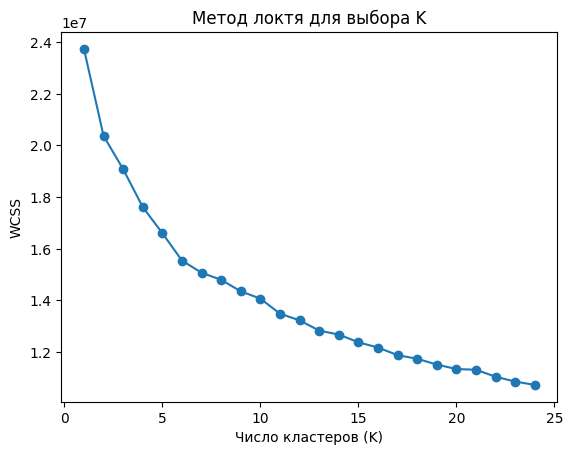

In [300]:
# Считаем WCSS для разных K
wcss = []
K_values = range(1, 25)

for k in K_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_dropna_scaled)
    wcss.append(kmeans.inertia_)  # inertia_ -- сумма квадратов расстояний точек до центроидов

# Строим график
plt.plot(K_values, wcss, marker='o', linestyle='-')
plt.xlabel("Число кластеров (K)")
plt.ylabel("WCSS")
plt.title("Метод локтя для выбора K")
plt.show()

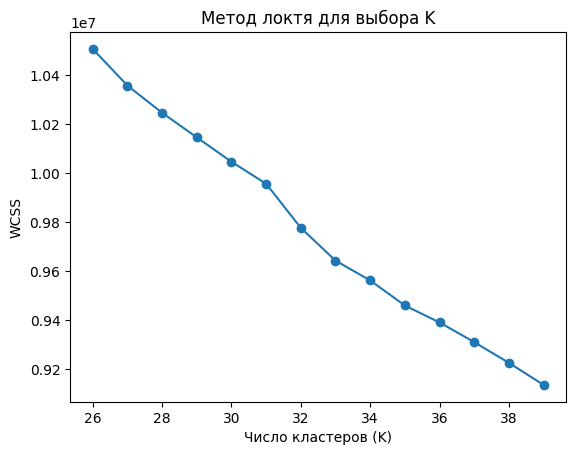

In [301]:
# Считаем WCSS для разных K
wcss = []
K_values = range(26, 40)

for k in K_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_dropna_scaled)
    wcss.append(kmeans.inertia_)  # inertia_ -- сумма квадратов расстояний точек до центроидов

# Строим график
plt.plot(K_values, wcss, marker='o', linestyle='-')
plt.xlabel("Число кластеров (K)")
plt.ylabel("WCSS")
plt.title("Метод локтя для выбора K")
plt.show()

In [302]:
# Обучаем алгоритм GaussianMixture
gmm = GaussianMixture(n_components=6, n_init=3)
gmm.fit(X_dropna_scaled)
labels_gmm = gmm.predict(X_fillna_scaled)

# Время обучения 15 минут Score 0.46013

In [314]:
# Присваиваем меткам кластеров порядковые номера
activity_ids_gmm = pd.factorize(labels_gmm)[0] + 1

df_submission = pd.DataFrame({
    'Index': range(0, len(activity_ids_gmm)),
    'activityID': activity_ids_gmm
})

df_submission.to_csv('submission.csv', index=False)

print(df_submission.head())

   Index  activityID
0      0           1
1      1           2
2      2           3
3      3           4
4      4           5


Выводы:

Были обучены модели KMeans, GaussianMixture а также сделаны предсказания на тестовых данных. Для воспроизводимости результатов использован фиксированный random_state.

Наилучший результат показала модель KMeans Score 0.54811 с количеством кластеров 6. Предпринята попытка использовать метод локтя для подбора оптимального количества кластеров, но различные попытки приводили к снижению результата, и лучший результат был показан на 6 кластерах. Также лучший результат был достигнут при обучении модели на датасете с удаленными пропусками.

Подбор гиперпараметров не привел к улучшению результата.

### 3. Закрепить в ноутбуке скриншот с лидерборда Kaggle.


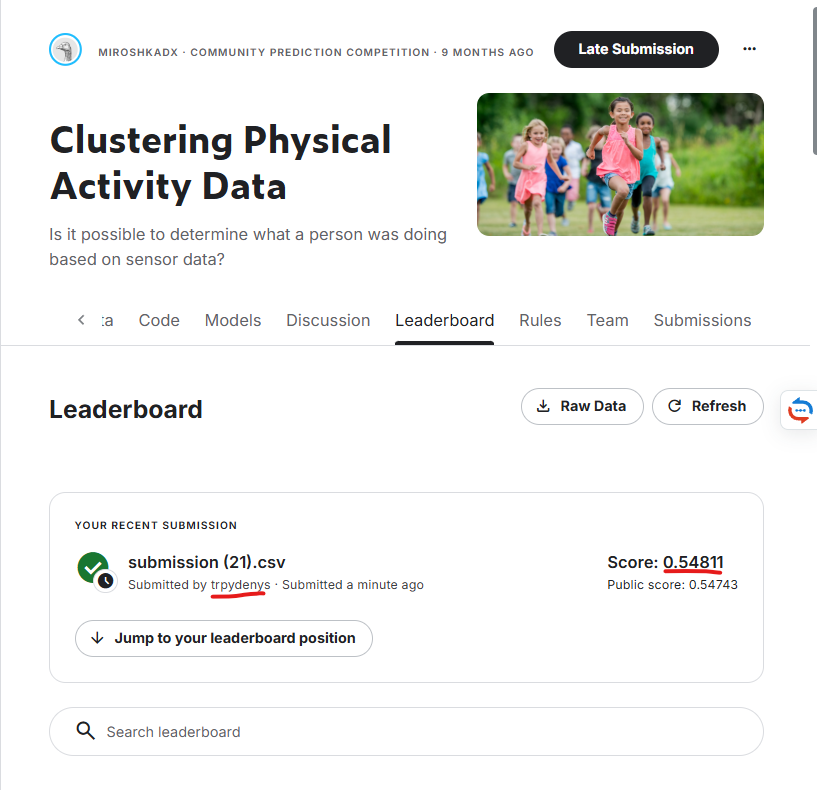